<a href="https://colab.research.google.com/github/georgekuttytom2004-eng/Assessment_3_supervised_Learning/blob/main/Assessment_3_Supervised_Georgekutty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Understanding and Exploratory Analysis


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/drive/MyDrive/DSAB13/Datasets/bank_marketing_assessment_dataset.csv')
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [11]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


In [3]:
df.shape

(600, 14)

In [4]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [5]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [6]:
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["subscribed"].value_counts()

,count
subscribed,
no,426
yes,174


In [9]:
df["subscribed"].value_counts(normalize=True) * 100

,proportion
subscribed,
no,71.0
yes,29.0


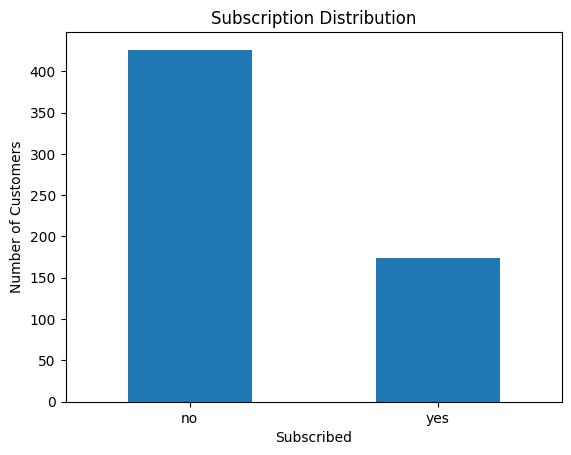

In [45]:
df['subscribed'].value_counts().plot(kind='bar')
plt.title("Subscription Distribution")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

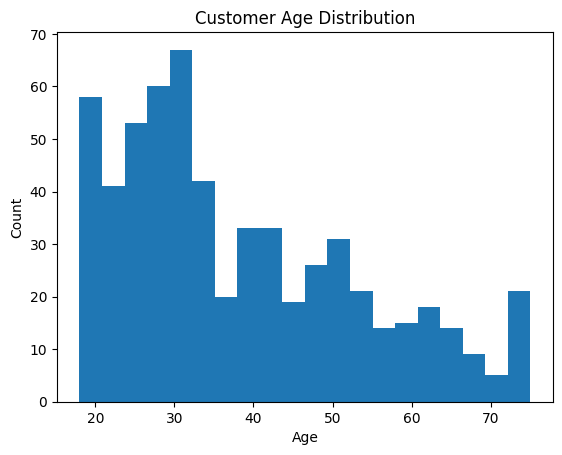

In [46]:
plt.hist(df['customer_age'], bins=20)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

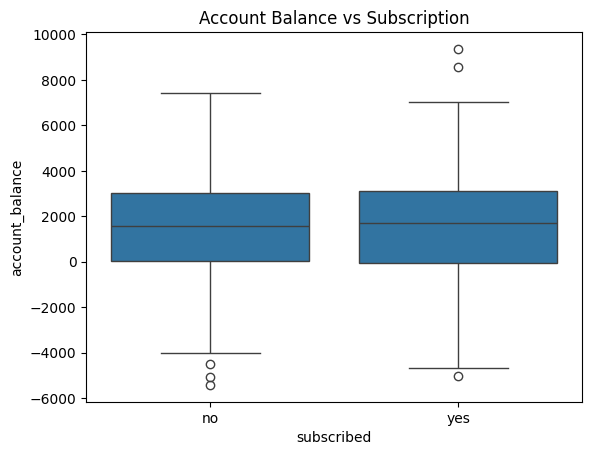

In [47]:
sns.boxplot(x='subscribed', y='account_balance', data=df)
plt.title("Account Balance vs Subscription")
plt.show()

2.
Data Preparation and Feature Engineering

In [28]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler




In [48]:
X = df.drop('subscribed', axis=1)
y = df['subscribed']
print(X.head())
print(y.head())

   customer_age         job marital_status  education  account_balance  \
0            69     retired       divorced  secondary           5467.0   
1            21       admin         single  secondary            606.0   
2            27  technician        married   tertiary           -314.0   
3            53  management         single  secondary           1503.0   
4            51  management         single  secondary           3037.0   

  housing_loan personal_loan contact_type contact_month  campaign_contacts  \
0           no            no      unknown           nov                  4   
1           no            no    telephone           may                  8   
2          yes            no     cellular           nov                 12   
3          yes           yes     cellular           nov                  6   
4           no            no      unknown           jun                  5   

   previous_contacts  engagement_score  annual_income_estimate  
0                  0 

In [49]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [50]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (480, 13)
Testing data: (120, 13)


In [51]:
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X_train.select_dtypes(include=['object']).columns

In [52]:
print("Numerical columns:")
print(numerical_columns)
print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
Index(['customer_age', 'account_balance', 'campaign_contacts',
       'previous_contacts', 'engagement_score', 'annual_income_estimate'],
      dtype='object')

Categorical columns:
Index(['job', 'marital_status', 'education', 'housing_loan', 'personal_loan',
       'contact_type', 'contact_month'],
      dtype='object')


In [53]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', categorical_pipeline, categorical_columns)
])

In [54]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (480, 31)
Processed testing data shape: (120, 31)


3.
Model Building

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [56]:
lr_model = LogisticRegression()
lr_model.fit(X_train_processed, y_train)
lr_pred = lr_model.predict(X_test_processed)

In [57]:
lr_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression())
])
lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)


In [58]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_processed, y_train)
dt_pred = dt_model.predict(X_test_processed)

In [59]:
dt_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)

4.
Model evaluation and comparison

In [60]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [61]:
lr_pred = lr_pipeline.predict(X_test)
dt_pred = dt_pipeline.predict(X_test)

In [62]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred,pos_label='yes')
lr_recall = recall_score(y_test, lr_pred,pos_label='yes')
lr_f1 = f1_score(y_test, lr_pred,pos_label='yes')
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

Accuracy: 0.8
Precision: 0.75
Recall: 0.5526315789473685
F1 Score: 0.6363636363636364


In [63]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, pos_label='yes')
dt_recall = recall_score(y_test, dt_pred, pos_label='yes')
dt_f1 = f1_score(y_test, dt_pred, pos_label='yes')
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

Accuracy: 0.7583333333333333
Precision: 0.6153846153846154
Recall: 0.631578947368421
F1 Score: 0.6233766233766234


In [64]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [lr_accuracy, dt_accuracy],
    'Precision': [lr_precision, dt_precision],
    'Recall': [lr_recall, dt_recall],
    'F1 Score': [lr_f1, dt_f1]
})
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.800000,0.750000,0.552632,0.636364
1,Decision Tree,0.758333,0.615385,0.631579,0.623377


In [65]:
lr_cm = confusion_matrix(y_test, lr_pred, labels=['no', 'yes'])
print(lr_cm)

[[75  7]
 [17 21]]


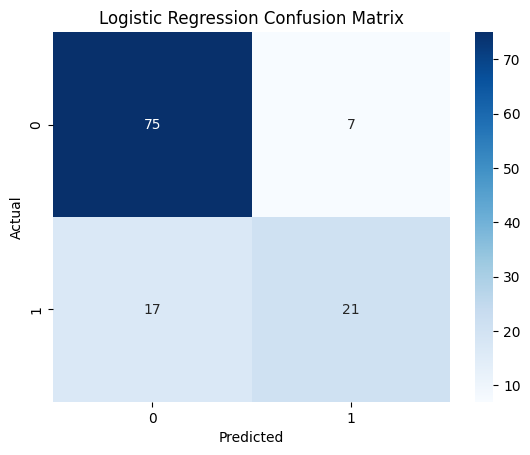

In [66]:
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [67]:
dt_cm = confusion_matrix(y_test, dt_pred, labels=['no', 'yes'])
print(dt_cm)

[[67 15]
 [14 24]]


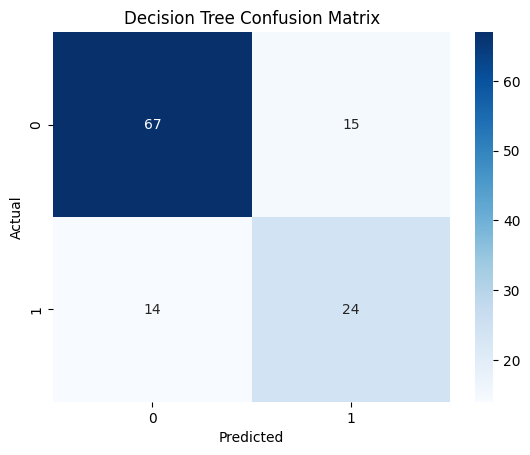

In [76]:
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### **Model Comparison and Recommendation**

Both Logistic Regression and Decision Tree models were evaluated using accuracy, precision, recall and F1-score. Logistic Regression performed better in terms of accuracy (80%) and F1-score (0.6364), whereas Decision Tree achieved a higher recall (0.6316). Since the bank aims to identify as many potential subscribers as possible and minimise missed opportunities, Decision Tree is a reasonable choice. However, Logistic Regression showed better overall performance in most evaluation metrics.

5.
Business Interpretation and Prediction

In [77]:
dt_model = dt_pipeline.named_steps['model']
feature_names = dt_pipeline.named_steps['preprocessing'].get_feature_names_out()
importance = dt_model.feature_importances_

In [78]:
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})
feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)
feature_df.head(10)

,Feature,Importance
20,cat__personal_loan_no,0.219268
5,num__annual_income_estimate,0.157551
0,num__customer_age,0.125491
1,num__account_balance,0.120260
4,num__engagement_score,0.104649
3,num__previous_contacts,0.100555
19,cat__housing_loan_yes,0.025463
2,num__campaign_contacts,0.022510
22,cat__contact_type_cellular,0.018566
8,cat__job_management,0.013033


### Feature Importance Interpretation

The feature importance analysis shows that personal_loan_no is the most influential feature, with an importance value of 0.219268. Other important features include annual_income_estimate, customer_age, account_balance, engagement_score and previous_contacts.

These features contribute significantly to the Decision Tree model's predictions. The bank can use these insights to understand which customer and campaign characteristics are useful for identifying potential subscribers.

**\*\*Limitation:\*\*** Feature importance only shows how much a feature contributes to the model's decisions. It does not prove that the feature directly causes a customer to subscribe.

give me this answers in other words

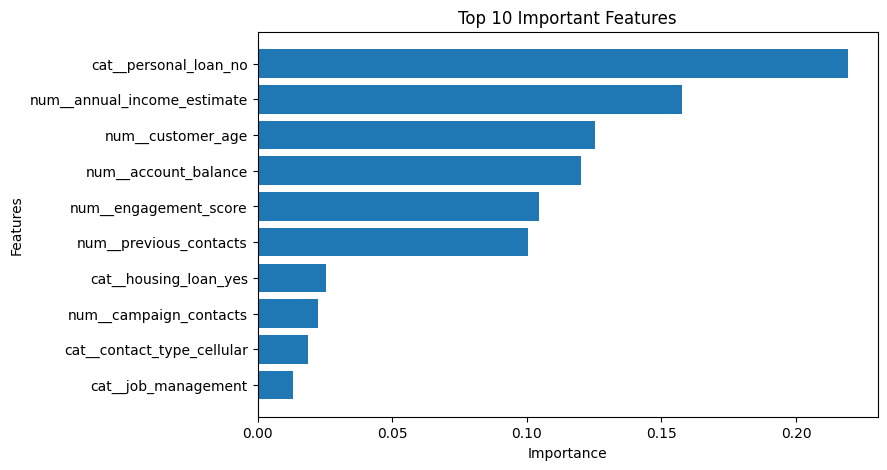

In [79]:
plt.figure(figsize=(8,5))
plt.barh(
    feature_df['Feature'].head(10),
    feature_df['Importance'].head(10)
)
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()

In [80]:
sample_data = X_test.head(5)
predictions = dt_pipeline.predict(sample_data)
print(predictions)
probabilities = dt_pipeline.predict_proba(sample_data)

['no' 'no' 'no' 'yes' 'no']


In [81]:
prediction_results = pd.DataFrame({
    'Actual': y_test.head(5).values,
    'Predicted': predictions,
    'Probability': probabilities[:, list(dt_pipeline.classes_).index('yes')]
})
prediction_results

,Actual,Predicted,Probability
0,yes,no,0.0
1,yes,no,0.0
2,no,no,0.0
3,no,yes,1.0
4,yes,no,0.0


### **Business Conclusion**

In this assessment, I built two machine learning models, Logistic Regression and Decision Tree, to predict whether customers would subscribe to a bank's term deposit. Logistic Regression achieved an accuracy of 80%, while Decision Tree obtained approximately 75.83%. Although Logistic Regression performed better in accuracy, Decision Tree provided a higher recall of 63.16%, meaning it was able to identify more actual subscribers. Therefore, Decision Tree is a suitable option when the bank wants to minimise the chances of missing potential customers. The feature analysis also highlighted personal loan status, annual income, customer age and account balance as important factors. As a future improvement, I would apply hyperparameter tuning to enhance the models' performance and minimise prediction errors.